In [22]:
%load_ext autoreload
%autoreload 2

from IPython.display import display, Markdown
import matplotlib.pyplot as plt
import seaborn as sns
import pylab as pl
import pandas as pd
import numpy as np
import scipy as sp
from scipy import stats
from sklearn.model_selection import KFold
import yaml
import shelve

from caa_model.config import *
from caa_model.utils.get_yaml_data import ERStruct, RTConf, reformat_revised_data

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Absolute Lower Bound

In [9]:
import pylab as pl
import shelve
from caa_model.utils.multinomial_funcs import multinom_loglike

db = shelve.open("data/neha_data_revised.yml.dat", "r")
DATA = db["empirical_results"]
db.close()

# QMPE forces these exact proportions per category based on your quantiles
bin_weights = pl.array([0.1, 0.2, 0.2, 0.2, 0.2, 0.1])

def get_qmpe_floor(rem_rts, know_rts, new_rts, rem_conf, know_conf, nr_conf_levels=3):
    N = len(rem_rts) + len(know_rts) + len(new_rts)
    if N == 0: return 0.0

    x_empirical = []
    p_perfect = []

    for i in range(nr_conf_levels):
        emp_i = (nr_conf_levels - 1) - i

        # Remember
        r_rts = rem_rts[rem_conf == emp_i]
        n_r = len(r_rts)
        if n_r > 0:
            x_empirical.extend(n_r * bin_weights)
            p_perfect.extend((n_r / N) * bin_weights)
        else:
            x_empirical.extend([0] * len(bin_weights))
            p_perfect.extend([0] * len(bin_weights))

        # Know
        k_rts = know_rts[know_conf == emp_i]
        n_k = len(k_rts)
        if n_k > 0:
            x_empirical.extend(n_k * bin_weights)
            p_perfect.extend((n_k / N) * bin_weights)
        else:
            x_empirical.extend([0] * len(bin_weights))
            p_perfect.extend([0] * len(bin_weights))

    # New
    n_new = len(new_rts)
    if n_new > 0:
        x_empirical.extend(n_new * bin_weights)
        p_perfect.extend((n_new / N) * bin_weights)
    else:
        x_empirical.extend([0] * len(bin_weights))
        p_perfect.extend([0] * len(bin_weights))

    x = pl.array(x_empirical)
    p = pl.array(p_perfect)

    # -multinom_loglike exactly as it is called in evaluate()
    return -multinom_loglike(x, N, p)

target_floor = get_qmpe_floor(DATA.rem_hit.rt, DATA.know_hit.rt, DATA.miss.rt, DATA.rem_hit.conf, DATA.know_hit.conf)
lure_floor = get_qmpe_floor(DATA.rem_fa.rt, DATA.know_fa.rt, DATA.CR.rt, DATA.rem_fa.conf, DATA.know_fa.conf)

print(f"Target NLL Floor: {target_floor:.2f}")
print(f"Lure NLL Floor: {lure_floor:.2f}")
print(f"Absolute QMPE NLL Floor: {target_floor + lure_floor:.2f}")

Target NLL Floor: 113.26
Lure NLL Floor: 106.26
Absolute QMPE NLL Floor: 219.52


## Inv Gauss Lower Bound

Finding optimal parameters for 14 independent curves (Takes ~5 seconds)...

Passing parameters into BaseDDM.evaluate()...

 BASEDDM EXACT QMPE LOWER BOUND
 TOTAL NLL FLOOR:      249.88


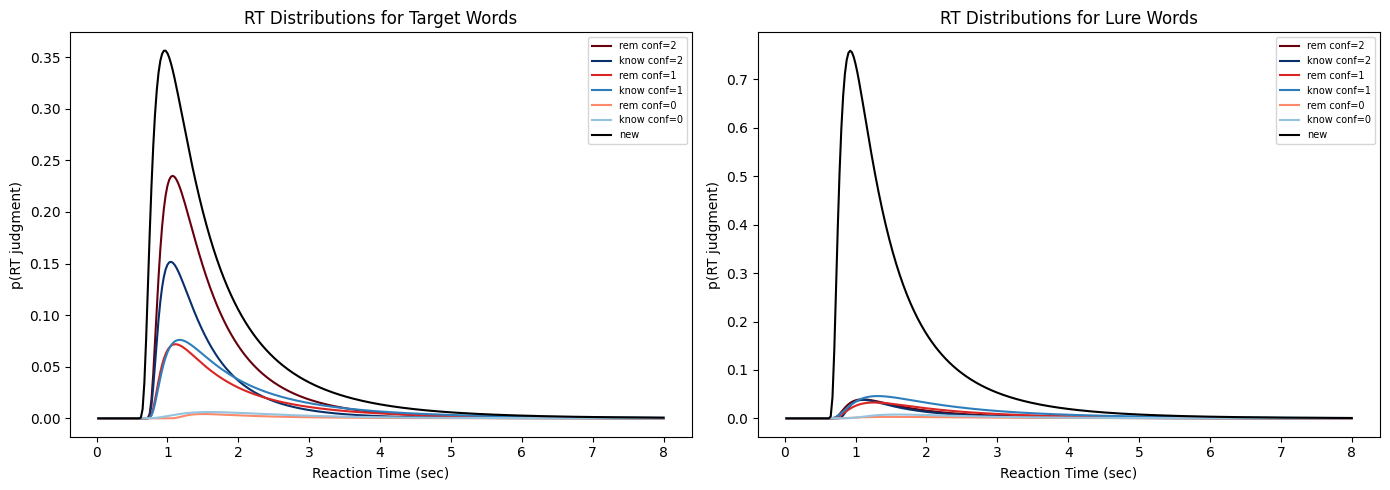

In [2]:
import numpy as np
import pylab as pl
from scipy import stats
from scipy.optimize import differential_evolution
from typing import NamedTuple

# IMPORT YOUR EXACT CODE
from caa_model.models.base_model import BaseDDM, DATA
from caa_model.config import EPS

class SaturatedIG(BaseDDM):
    """
    Subclasses BaseDDM.
    Keeps all QMPE evaluation methods identical but replaces diffusion
    with 14 Independent Inverse Gaussians in predicted_proportions.
    """
    class Params(NamedTuple):
        # Targets (21 params)
        tr2_m: float; tr2_s: float; tr2_l: float
        tr1_m: float; tr1_s: float; tr1_l: float
        tr0_m: float; tr0_s: float; tr0_l: float
        tk2_m: float; tk2_s: float; tk2_l: float
        tk1_m: float; tk1_s: float; tk1_l: float
        tk0_m: float; tk0_s: float; tk0_l: float
        tn_m:  float; tn_s:  float; tn_l:  float

        # Lures (21 params)
        lr2_m: float; lr2_s: float; lr2_l: float
        lr1_m: float; lr1_s: float; lr1_l: float
        lr0_m: float; lr0_s: float; lr0_l: float
        lk2_m: float; lk2_s: float; lk2_l: float
        lk1_m: float; lk1_s: float; lk1_l: float
        lk0_m: float; lk0_s: float; lk0_l: float
        ln_m:  float; ln_s:  float; ln_l:  float

    @staticmethod
    def split_params(model_params):
        return (model_params[:21], True), (model_params[21:], False)

    def predicted_proportions(self, params):
        ig_params, is_target = params
        delta_t = self.config.delta_t
        t = pl.linspace(delta_t, self.config.max_t, self.config.nr_tsteps)

        # Pull exact human data to calculate category weights
        if is_target:
            r_rts, k_rts, n_rts = DATA.rem_hit.rt, DATA.know_hit.rt, DATA.miss.rt
            r_c, k_c = DATA.rem_hit.conf, DATA.know_hit.conf
        else:
            r_rts, k_rts, n_rts = DATA.rem_fa.rt, DATA.know_fa.rt, DATA.CR.rt
            r_c, k_c = DATA.rem_fa.conf, DATA.know_fa.conf

        N = len(r_rts) + len(k_rts) + len(n_rts)
        if N == 0: N = 1

        def get_mass(mu, scale, loc, rts, conf, level=None):
            count = len(rts[conf == level]) if level is not None else len(rts)
            weight = count / N
            if weight <= EPS:
                return pl.zeros_like(t)
            pdf = stats.invgauss.pdf(t, mu, loc=loc, scale=scale)
            pdf = pl.nan_to_num(pdf)
            return pdf * delta_t * weight

        p_rem = pl.zeros((3, len(t)))
        p_know = pl.zeros((3, len(t)))

        for i in range(3):
            emp_level = 2 - i

            b_rem = i * 3
            p_rem[i] = get_mass(ig_params[b_rem], ig_params[b_rem+1], ig_params[b_rem+2], r_rts, r_c, emp_level)

            b_know = (i + 3) * 3
            p_know[i] = get_mass(ig_params[b_know], ig_params[b_know+1], ig_params[b_know+2], k_rts, k_c, emp_level)

        p_new = get_mass(ig_params[18], ig_params[19], ig_params[20], n_rts, None)

        return p_rem, p_know, p_new, t


# --- Fast parameter finder (bypasses 42-param DE slowdown) ---
def find_best_3_params(rts, max_t=6.0, lapse_rate=0.02):
    if len(rts) == 0:
        return [1.0, 1.0, 0.0]

    q_edges = np.quantile(rts, [0.1, 0.3, 0.5, 0.7, 0.9])
    bounds = np.concatenate(([0.0], q_edges, [np.inf]))
    expected_props = np.array([0.1, 0.2, 0.2, 0.2, 0.2, 0.1])
    x_emp = len(rts) * expected_props

    def objective(p):
        mu, scale, loc = p
        cdf_vals = stats.invgauss.cdf(bounds, mu, loc=loc, scale=scale)
        p_pred = np.diff(cdf_vals)
        uniform_p = np.diff(np.clip(bounds / max_t, 0.0, 1.0))
        p_mix = (1.0 - lapse_rate) * p_pred + lapse_rate * uniform_p
        p_mix = np.clip(p_mix / np.sum(p_mix), EPS, 1.0)
        return -np.sum(x_emp * np.log(p_mix))

    res = differential_evolution(objective, [(EPS, 5.0), (EPS, 5.0), (-0.5, 1.5)], strategy="best1bin")
    return res.x.tolist()


if __name__ == "__main__":
    print("Finding optimal parameters for 14 independent curves (Takes ~5 seconds)...")

    # 1. Gather all 42 optimal parameters dynamically
    t_params = []
    t_params.extend(find_best_3_params(DATA.rem_hit.rt[DATA.rem_hit.conf == 2]))
    t_params.extend(find_best_3_params(DATA.rem_hit.rt[DATA.rem_hit.conf == 1]))
    t_params.extend(find_best_3_params(DATA.rem_hit.rt[DATA.rem_hit.conf == 0]))
    t_params.extend(find_best_3_params(DATA.know_hit.rt[DATA.know_hit.conf == 2]))
    t_params.extend(find_best_3_params(DATA.know_hit.rt[DATA.know_hit.conf == 1]))
    t_params.extend(find_best_3_params(DATA.know_hit.rt[DATA.know_hit.conf == 0]))
    t_params.extend(find_best_3_params(DATA.miss.rt))

    l_params = []
    l_params.extend(find_best_3_params(DATA.rem_fa.rt[DATA.rem_fa.conf == 2]))
    l_params.extend(find_best_3_params(DATA.rem_fa.rt[DATA.rem_fa.conf == 1]))
    l_params.extend(find_best_3_params(DATA.rem_fa.rt[DATA.rem_fa.conf == 0]))
    l_params.extend(find_best_3_params(DATA.know_fa.rt[DATA.know_fa.conf == 2]))
    l_params.extend(find_best_3_params(DATA.know_fa.rt[DATA.know_fa.conf == 1]))
    l_params.extend(find_best_3_params(DATA.know_fa.rt[DATA.know_fa.conf == 0]))
    l_params.extend(find_best_3_params(DATA.CR.rt))

    best_42_params = t_params + l_params

    # 2. Feed them strictly into YOUR evaluate pipeline
    print("\nPassing parameters into BaseDDM.evaluate()...")
    model = SaturatedIG()
    eval_result = model.evaluate(best_42_params, method="qmpe")
    params_opt = eval_result.params

    print("\n==============================================")
    print(" BASEDDM EXACT QMPE LOWER BOUND")
    print("==============================================")
    print(f" TOTAL NLL FLOOR:      {eval_result.nll:.2f}")
    print("==============================================")

    model.plot_rt_distributions(params_opt)

## SISP Lower Bound

Evaluating Corrected SISPOptimalWeights...

 CORRECTED SISP 'SINGLE SHAPE' MATHEMATICAL LIMIT
 TOTAL NLL:            378.30


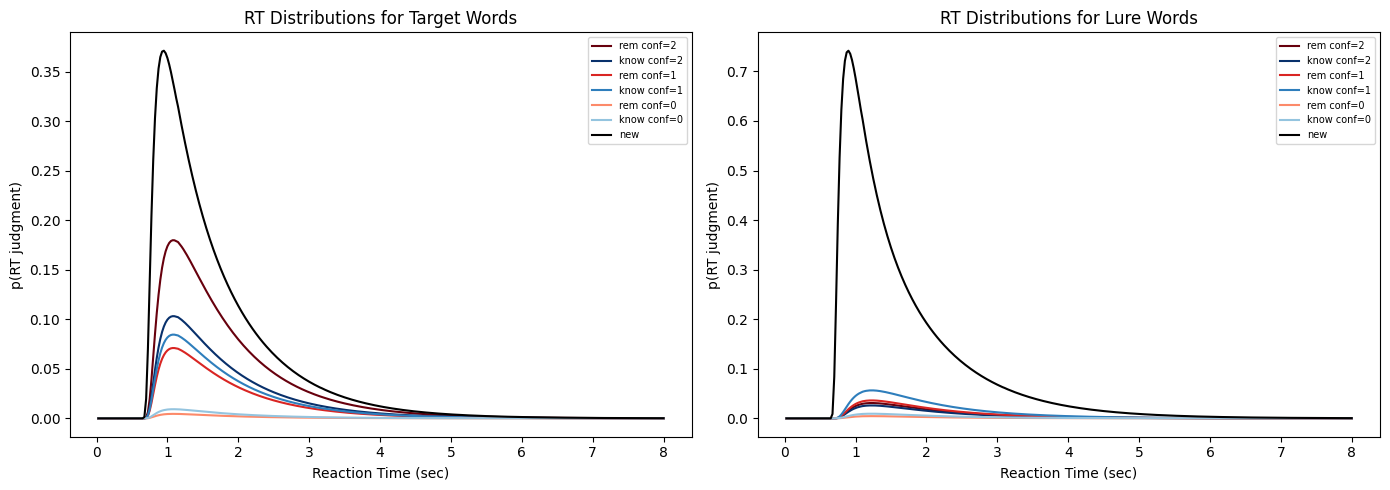

In [8]:
import numpy as np
import pylab as pl
from scipy import stats
from typing import NamedTuple

# IMPORT YOUR EXACT CODE
from caa_model.models.base_model import BaseDDM, DATA
from caa_model.config import EPS

class SISPOptimalWeights(BaseDDM):
    """
    Tests the absolute mathematical limit of the SISP 'Single Shape' assumption.
    Generates one shape (p_old) and slices it using the mathematically perfect
    empirical weights, completely bypassing the MVN confidence mechanics.
    """
    class Params(NamedTuple):
        mu_t: float      # Target drift
        mu_l: float      # Lure drift
        d_t: float       # Target diffusion
        d_l: float       # Lure diffusion
        tc_bound: float  # Boundary collapse rate
        z0_t: float      # Target starting point
        z0_l: float      # Lure starting point
        t0: float        # Non-decision time

    @staticmethod
    def split_params(model_params):
        mu_t, mu_l, d_t, d_l, tc, z0_t, z0_l, t0 = model_params
        target_params = (mu_t, d_t, tc, z0_t, t0, True)
        lure_params = (mu_l, d_l, tc, z0_l, t0, False)
        return target_params, lure_params

    def predicted_proportions(self, params):
        mu_r, d, tc_bound, z0, t0, is_target = params
        delta_t = self.config.delta_t
        max_t = self.config.max_t
        nr_tsteps = self.config.nr_tsteps
        nr_ssteps = self.config.nr_ssteps

        # 1. GET EXACT HUMAN PROPORTIONS FOR OPTIMAL WEIGHTING
        if is_target:
            r_c = DATA.rem_hit.conf
            k_c = DATA.know_hit.conf
        else:
            r_c = DATA.rem_fa.conf
            k_c = DATA.know_fa.conf

        # Calculate exact counts of old responses
        n_rem = [np.sum(r_c == i) for i in (2, 1, 0)]   # High, Med, Low
        n_know = [np.sum(k_c == i) for i in (2, 1, 0)]
        total_old = sum(n_rem) + sum(n_know)
        if total_old == 0: total_old = 1

        # The mathematically perfect scalar weights for the p_old curve
        w_rem = [n / total_old for n in n_rem]
        w_know = [n / total_old for n in n_know]

        # 2. STANDARD DDM PHYSICS (1D FFT)
        sigma = pl.sqrt(2 * d * delta_t)
        mu = mu_r * delta_t
        t = pl.linspace(delta_t, max_t, nr_tsteps)
        to_idx = pl.argmin((t - t0) ** 2)

        bound = pl.exp(-tc_bound * pl.clip(t - t0, 0, None))
        space_lim = max(bound) + 3 * sigma
        delta_s = 2 * space_lim / nr_ssteps
        x = pl.linspace(-space_lim, space_lim, nr_ssteps)

        kernel = stats.norm.pdf(x, mu, sigma) * delta_s
        ft_kernel = self._fft(kernel)

        tx = pl.zeros((len(t), len(x)))
        p_old = pl.zeros(pl.shape(t))
        p_new = pl.zeros(pl.shape(t))

        tx[to_idx] = stats.norm.pdf(x, mu + z0, sigma) * delta_s

        for i in range(to_idx, len(t)):
            if i > to_idx:
                tx[i] = abs(pl.ifftshift(self._ifft(self._fft(tx[i - 1]) * ft_kernel)))

            p_pos = tx[i][x >= bound[i]]
            p_old[i] = pl.sum(p_pos)
            p_new[i] = pl.sum(tx[i][x <= -bound[i]])
            tx[i] *= abs(x) < bound[i]

        # 3. SLICE USING PERFECT EMPIRICAL WEIGHTS (Bypassing MVN)
        p_rem_conf = pl.zeros((3, len(t)))
        p_know_conf = pl.zeros((3, len(t)))

        for i in range(3):
            p_rem_conf[i] = p_old * w_rem[i]
            p_know_conf[i] = p_old * w_know[i]

        return p_rem_conf, p_know_conf, p_new, t


param_bounds = (
    SISPOptimalWeights.Params(
        mu_t=-2.0, mu_l=-2.0, d_t=EPS, d_l=EPS, tc_bound=0.0, z0_t=-2.0, z0_l=-2.0, t0=0.0
    ),
    SISPOptimalWeights.Params(
        mu_t=2.0, mu_l=2.0, d_t=2.0, d_l=2.0, tc_bound=2.0, z0_t=2.0, z0_l=2.0, t0=1.0
    ),
)

if __name__ == "__main__":
    print("Fitting 8-parameter SISPOptimalWeights globally...")
    model = SISPOptimalWeights()

    # Run global DE optimizer
    # best_params = model.fit(param_bounds, method="qmpe", nr_workers=-1)
    best_params = SISPOptimalWeights.Params(mu_t=np.float64(0.28489136956539063), mu_l=np.float64(-0.27404204913219576), d_t=np.float64(0.5206024074216395), d_l=np.float64(0.46747531512446144), tc_bound=np.float64(0.00018025334386595078), z0_t=np.float64(-0.10370931686122954), z0_l=np.float64(-0.22664052399356907), t0=np.float64(0.6556197875679692))
    eval_result = model.evaluate(best_params, method="qmpe")

    print("\n==============================================")
    print(" SISP 'SINGLE SHAPE' MATHEMATICAL LIMIT")
    print("==============================================")
    print(f" TOTAL NLL:            {eval_result.nll:.2f}")
    print("==============================================")

    model.plot_rt_distributions(best_params)

## Wiener Aggregated

Fitting 8-parameter Macroscopic SISP/DISP Limit...


differential_evolution step 1: f(x)= 4457.947316282554
differential_evolution step 2: f(x)= 3695.512050342306
differential_evolution step 3: f(x)= 3396.250226785256
differential_evolution step 4: f(x)= 3396.250226785256
differential_evolution step 5: f(x)= 2245.952172399855
differential_evolution step 6: f(x)= 1742.4691869464968
differential_evolution step 7: f(x)= 1106.2497335413918
differential_evolution step 8: f(x)= 914.8327609041353
differential_evolution step 9: f(x)= 744.4641667839369
differential_evolution step 10: f(x)= 744.4641667839369
differential_evolution step 11: f(x)= 744.4641667839369
differential_evolution step 12: f(x)= 744.4641667839369
differential_evolution step 13: f(x)= 744.4641667839369
differential_evolution step 14: f(x)= 744.4641667839369
differential_evolution step 15: f(x)= 734.9573815561889
differential_evolution step 16: f(x)= 734.9573815561889
differential_evolution step 17: f(x)= 734.9573815561889
differential_evolution step 18: f(x)= 493.6408064016850

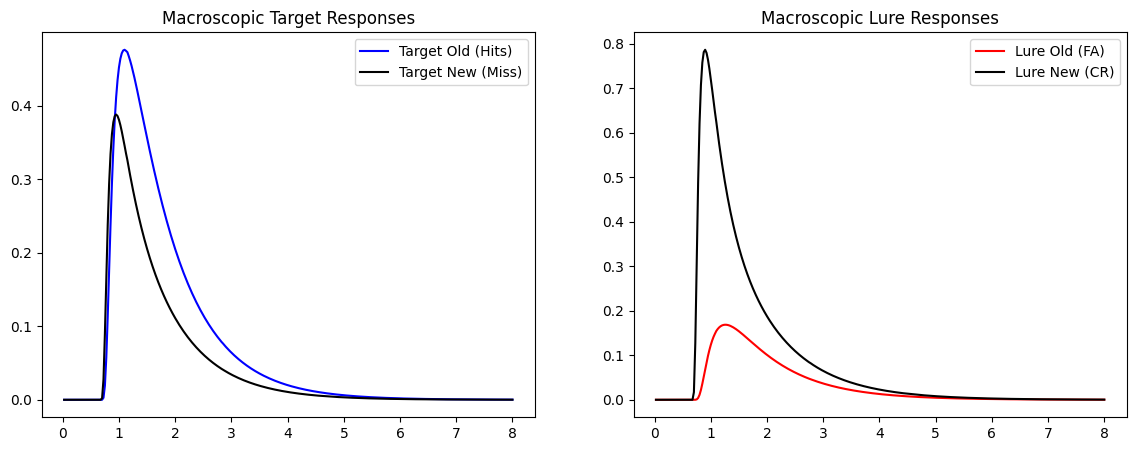

In [11]:
import numpy as np
import pylab as pl
from scipy import stats
from typing import NamedTuple
import matplotlib.pyplot as plt

# IMPORT YOUR EXACT CODE
from caa_model.models.base_model import BaseDDM, DATA
from caa_model.config import EPS
from caa_model.utils.multinomial_funcs import multinom_loglike

class MacroscopicSISP(BaseDDM):
    """
    Tests the absolute macroscopic limit of Single-Accumulator models (SISP/DISP).
    Aggregates all confidence and R/K judgments into a binary 'Old vs New' choice.
    Evaluates the pure 2-boundary FFT simulation against the aggregated empirical data.
    """
    class Params(NamedTuple):
        mu_t: float      # Target drift
        mu_l: float      # Lure drift
        d_t: float       # Target diffusion
        d_l: float       # Lure diffusion
        tc_bound: float  # Boundary collapse rate
        z0_t: float      # Target starting point
        z0_l: float      # Lure starting point
        t0: float        # Non-decision time

    @staticmethod
    def split_params(model_params):
        mu_t, mu_l, d_t, d_l, tc, z0_t, z0_l, t0 = model_params
        target_params = (mu_t, d_t, tc, z0_t, t0, True)
        lure_params = (mu_l, d_l, tc, z0_l, t0, False)
        return target_params, lure_params

    def predicted_proportions(self, params):
        """
        Pure 1D FFT simulation. Returns ONLY p_old and p_new mass arrays.
        """
        mu_r, d, tc_bound, z0, t0, is_target = params
        delta_t = self.config.delta_t
        max_t = self.config.max_t
        nr_tsteps = self.config.nr_tsteps
        nr_ssteps = self.config.nr_ssteps

        sigma = pl.sqrt(2 * d * delta_t)
        mu = mu_r * delta_t
        t = pl.linspace(delta_t, max_t, nr_tsteps)
        to_idx = pl.argmin((t - t0) ** 2)

        bound = pl.exp(-tc_bound * pl.clip(t - t0, 0, None))
        space_lim = max(bound) + 3 * sigma
        delta_s = 2 * space_lim / nr_ssteps
        x = pl.linspace(-space_lim, space_lim, nr_ssteps)

        kernel = stats.norm.pdf(x, mu, sigma) * delta_s
        ft_kernel = self._fft(kernel)

        tx = pl.zeros((len(t), len(x)))
        p_old = pl.zeros(pl.shape(t))
        p_new = pl.zeros(pl.shape(t))

        tx[to_idx] = stats.norm.pdf(x, mu + z0, sigma) * delta_s

        for i in range(to_idx, len(t)):
            if i > to_idx:
                tx[i] = abs(pl.ifftshift(self._ifft(self._fft(tx[i - 1]) * ft_kernel)))

            # Upper boundary hits (Old)
            p_pos = tx[i][x >= bound[i]]
            p_old[i] = pl.sum(p_pos)

            # Lower boundary hits (New)
            p_new[i] = pl.sum(tx[i][x <= -bound[i]])

            tx[i] *= abs(x) < bound[i]

        return p_old, p_new, t

    def compute_gof_all(self, model_params, data=DATA, method="qmpe", use_chisq=False):
        """
        Overrides BaseDDM to compute GOF strictly on 2 choices: Old vs New.
        """
        try:
            t_params, l_params = self.split_params(model_params)

            # Get physical shapes from FFT
            p_old_t, p_new_t, t = self.predicted_proportions(t_params)
            p_old_l, p_new_l, t = self.predicted_proportions(l_params)

            # Aggregate human data into 2 choices
            t_old_rts = np.concatenate([data.rem_hit.rt, data.know_hit.rt])
            t_new_rts = data.miss.rt
            l_old_rts = np.concatenate([data.rem_fa.rt, data.know_fa.rt])
            l_new_rts = data.CR.rt

            # Run 2-choice QMPE matching your exact pipeline
            nll_target = self._qmpe_2choice(t_old_rts, t_new_rts, p_old_t, p_new_t, t)
            nll_lure = self._qmpe_2choice(l_old_rts, l_new_rts, p_old_l, p_new_l, t)

            total_nll = nll_target + nll_lure
            if pl.isnan(total_nll) or pl.isinf(total_nll):
                return 1e9
            return total_nll
        except Exception:
            return 1e9

    def _qmpe_2choice(self, rts_old, rts_new, p_old_mass, p_new_mass, t, lapse_rate=0.02):
        N = len(rts_old) + len(rts_new)
        if N == 0: return 0.0

        internal_cuts = pl.array(self.config.quantiles)
        q_edges = pl.hstack([0.0, internal_cuts, 1.0])
        bin_weights = pl.diff(q_edges)
        nr_bins = len(bin_weights)

        # 2 Choices: Old and New
        num_choices = 2
        uniform_cdf = pl.clip(t / self.config.max_t, 0.0, 1.0) * (1.0 / num_choices)

        # Convert mass to CDFs
        cdf_old = pl.cumsum(p_old_mass)
        cdf_new = pl.cumsum(p_new_mass)

        # Mix with lapse rate
        unnorm_old = (1.0 - lapse_rate) * cdf_old + lapse_rate * uniform_cdf
        unnorm_new = (1.0 - lapse_rate) * cdf_new + lapse_rate * uniform_cdf

        x_empirical = []
        p_predicted = []

        for rts, unnorm_cdf in zip([rts_old, rts_new], [unnorm_old, unnorm_new]):
            if len(rts) > 0:
                emp_bounds = pl.quantile(rts, q_edges)
                emp_bounds[0] = 0.0
                emp_bounds[-1] = pl.inf

                counts, _ = pl.histogram(rts, bins=emp_bounds)
                x_empirical.extend(counts)

                model_cdf_at_bounds = pl.append(
                    pl.interp(emp_bounds[:-1], t, unnorm_cdf, left=0.0, right=unnorm_cdf[-1]),
                    unnorm_cdf[-1]
                )
                p_predicted.extend(pl.diff(model_cdf_at_bounds))
            else:
                x_empirical.extend([0] * nr_bins)
                p_predicted.extend(unnorm_cdf[-1] * bin_weights)

        x = pl.array(x_empirical)
        p = pl.array(p_predicted)

        p_sum = pl.sum(p)
        if p_sum == 0.0: return 1e9

        p = p / p_sum
        p = pl.clip(p, EPS, 1.0)

        return -multinom_loglike(x, N, p)

    def plot_macro_distributions(self, params):
        """Custom plotter for the 2-choice model."""
        delta_t = self.config.delta_t
        t_params, l_params = self.split_params(params)

        p_old_t, p_new_t, t = self.predicted_proportions(t_params)
        p_old_l, p_new_l, t = self.predicted_proportions(l_params)

        fig, axes = plt.subplots(1, 2, figsize=(14, 5))

        axes[0].plot(t, p_old_t / delta_t, color='blue', label="Target Old (Hits)")
        axes[0].plot(t, p_new_t / delta_t, color='black', label="Target New (Miss)")
        axes[0].set_title("Macroscopic Target Responses")
        axes[0].legend()

        axes[1].plot(t, p_old_l / delta_t, color='red', label="Lure Old (FA)")
        axes[1].plot(t, p_new_l / delta_t, color='black', label="Lure New (CR)")
        axes[1].set_title("Macroscopic Lure Responses")
        axes[1].legend()

        plt.show()

# --- RUN GLOBAL OPTIMIZATION ---
param_bounds = (
    MacroscopicSISP.Params(
        mu_t=-2.0, mu_l=-2.0, d_t=EPS, d_l=EPS, tc_bound=0.0, z0_t=-2.0, z0_l=-2.0, t0=0.0
    ),
    MacroscopicSISP.Params(
        mu_t=2.0, mu_l=2.0, d_t=2.0, d_l=2.0, tc_bound=2.0, z0_t=2.0, z0_l=2.0, t0=1.0
    ),
)

if __name__ == "__main__":
    print("Fitting 8-parameter Macroscopic SISP/DISP Limit...")
    model = MacroscopicSISP()

    # Let Differential Evolution find the absolute best macroscopic shape
    best_params = model.fit(param_bounds, method="qmpe", nr_workers=-1)
    eval_result = model.evaluate(best_params, method="qmpe")

    print("\n==============================================")
    print(" TRUE MACROSCOPIC LIMIT (SISP & DISP)")
    print("==============================================")
    print(f" AGGREGATED TOTAL NLL:     {eval_result.nll:.2f}")
    print("==============================================")

    model.plot_macro_distributions(best_params)